# 05 — Második intelligenciaréteg: tematikus kategorizálás / Layer 2: thematic categorisation

HU: Az első réteg megmondja, **milyen** egy mondat (negatív / semleges / pozitív). A második réteg két szinten
mondja meg, **miről** és **pontosan mi miatt**:

```
mondat ──► [1. réteg] szentiment (B)              → negatív / semleges / pozitív
       ──► [2/a] aspektus-osztályozó (HRAST, BERT) → MIRŐL szól?   pl. bathroom
       ──► [2/b] altémák (beágyazás + fürtözés)    → MI A GOND?    pl. „nincs meleg víz”
```

| # | Lépés / Step | Mérés / Measurement | Dolgozat / Thesis |
|---|---|---|---|
| 1 | 2/a tanítás a HRAST-on / training on HRAST | aspektusonkénti F1 a HRAST-teszten, vs. kulcsszólista | 3.4, 3.5 |
| 2 | 2/a alkalmazás a Booking-mondatokra / applying to Booking | egyezés a kulcsszólistával | 3.5 |
| 3 | 2/b altémák aspektusonként / subtopics per aspect | NPMI-koherencia, diverzitás, stabilitás (ARI) | 3.4, 3.5 |
| 4 | Panasztérkép / complaint map | lift szegmensenként | 3.5 |
| 5 | Kézi ellenőrzés / manual check | témánkénti pontosság | 3.5 |

**Előfeltétel / Prerequisites:** a (B) modell (`results/models/approach_b_hrast`), a HRAST CSV a `data/raw/hrast/`
mappában, és `pip install sentence-transformers umap-learn`.
**Elemzési egység / Analysis unit:** tagmondat, a dicséret- és panaszmezőből KÜLÖN bontva / clause, split SEPARATELY
from the praise and complaint fields. GPU ajánlott (a 2/a tanítás kb. 10–15 perc).

## 1. Környezet és adatok / Environment and data

In [1]:
# HU: A notebooks/ mappából futunk, ezért a szülőmappát a path-hoz adjuk (src csomag).
# EN: We run from the notebooks/ folder, so the parent folder is added to the path (src package).
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import set_seed
from src.config import CFG, PATHS, SENTIMENT_COLORS, INK, APPROACHES, apply_plot_style
from src import data_loading as dl
from src import preprocessing as pp
from src import evaluation as ev
from src import descriptives as ds
from src import aspects as asp
from src import aspect_model as am
from src import topic_modeling as tm
from src import pipeline

# HU: Reprodukálhatóság + egységes ábrastílus. / EN: Reproducibility + uniform figure style.
set_seed()
PATHS.ensure()
apply_plot_style()
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 170)

# HU: ELEMZÉSI EGYSÉGEK: a dicséret- és a panaszmezőt KÜLÖN bontjuk tagmondatokra (pont, pontosvessző,
#     "but / however / although" mentén), így a kettő nem olvad egy "mondatba". Minden egységre lefut a
#     (B) modell is (kb. 5–10 perc, darabolva, folytatható).
# EN: ANALYSIS UNITS: the praise and the complaint field are split into clauses SEPARATELY (at full stops,
#     semicolons, "but / however / although"), so the two never merge into one "sentence". The (B) model
#     also runs on every unit (about 5–10 min, chunked, resumable).
from src import bert_labelling as bl
meta = ds.prepare_star_rating(dl.read_frame(pipeline.LABELLED))
units = pp.build_field_units(meta)
scorer_b = bl.TransformerScorer(str(PATHS.models / "approach_b_hrast"))
sent = bl.predict_units(units, "", "B", cache_name="B_field_units", scorer=scorer_b)

meta_cols = ["review_id", "score", "label_final", "accommodation_type", "accommodation_country",
             "guest_type", "accommodation_star_rating"]
sent = sent.merge(meta[[c for c in meta_cols if c in meta.columns]], on="review_id", how="left")
dl.write_frame(sent, PATHS.labels / "field_units_B")
print(f"{len(sent):,} units from {sent['review_id'].nunique():,} reviews")

# HU: Mezőpolaritás × (B)-címke: mennyire ért egyet a modell a vendég saját besorolásával?
# EN: Field polarity × (B) label: how far does the model agree with the guest's own classification?
display(pd.crosstab(sent["field_polarity"], sent["B_label"], normalize="index").round(3))

17:12:52 | INFO    | src.preprocessing | Field units: 85638 from 19969 reviews | by field: {'positive': 58897, 'negative': 26741}
17:13:21 | INFO    | src.bert_labelling | Loading model: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\models\approach_b_hrast (device: cuda, fp16: True)


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

17:13:23 | INFO    | src.bert_labelling | Model type: 3class | labels: ['negative', 'neutral', 'positive']
17:13:23 | INFO    | src.bert_labelling | [B_field_units] chunk 1/9 (10000 texts)
17:13:25 | INFO    | src.bert_labelling |   C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\models\approach_b_hrast: 50/157 batches (1590 texts/s)
17:13:26 | INFO    | src.bert_labelling |   C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\models\approach_b_hrast: 100/157 batches (1819 texts/s)
17:13:28 | INFO    | src.bert_labelling |   C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\models\approach_b_hrast: 150/157 batches (1685 texts/s)
17:13:29 | INFO    | src.bert_labelling | [B_field_units] chunk 2/9 (10000 texts)
17:13:30 | INFO    | src.bert_labelling |   C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\models\approach_b_hrast: 50/157 batches (2924 texts/s)
17:13:32 | INFO    | src.bert_labelling |   C:\User

85,638 units from 19,969 reviews


B_label,negative,neutral,positive
field_polarity,,,
negative,0.737,0.079,0.184
positive,0.067,0.029,0.904


## 2. 2/a — Aspektus-osztályozó a HRAST-on / Aspect classifier on HRAST

HU: Többcímkés BERT: aspektusonként egy igen/nem döntés (szigmoid). A ritka aspektusok nagyobb súlyt kapnak
(`pos_weight`), a döntési küszöböt aspektusonként a **validációs** halmazon hangoljuk, a végső mérés a **teszthalmazon**
történik — és ugyanott mérjük a kulcsszólistát is (alapvonal).

EN: Multi-label BERT: one yes/no decision per aspect (sigmoid). Rare aspects get a larger weight (`pos_weight`), the
decision threshold is tuned per aspect on the **validation** set, the final measurement is on the **test** set — where
the keyword list (baseline) is measured too.

In [2]:
hrast_raw = dl.load_hrast_raw()
asp_data, ASPECTS = am.prepare_hrast_aspects(hrast_raw)
counts = asp_data[ASPECTS].sum().sort_values(ascending=False).to_frame("sentences")
counts["share"] = (counts["sentences"] / len(asp_data)).round(4)
display(counts); ev.save_table(counts, "05_hrast_aspect_counts")

17:15:28 | INFO    | src.data_loading | HRAST loaded: hrast.csv — 23113 rows, columns: ['id', 'review', 'Unnamed: 2', 'positive', 'negative', 'neutral', 'Clean', 'Comfort', 'Facilities/Amenities', 'Location', 'Restaurant (dinner)', 'Staff', 'View (Balcony)', 'Breakfast', 'Room', 'Pool', 'Beach', 'Bathroom/Shower (toilet)', 'Bar', 'Bed', 'Parking', 'Noise', 'Reception-checkin', 'Lift', 'Value for money', 'Wi-Fi', 'Generic', 'Aspect']
17:15:28 | INFO    | src.aspect_model | HRAST aspect data: 23105 sentences, 21 aspects | without aspect: 0.0%


,sentences,share
room,5004,0.2166
location,4727,0.2046
staff,3800,0.1645
cleanliness,2926,0.1266
facilities,2923,0.1265
comfort,2561,0.1108
breakfast,2539,0.1099
bathroom,2344,0.1014
generic,1973,0.0854
noise,1604,0.0694


17:15:28 | INFO    | src.evaluation | Table saved: 05_hrast_aspect_counts.csv


WindowsPath('C:/Users/seszt/Documents/BCE/7_felev/Szakdolgozat/THESIS/CODE/results/tables/05_hrast_aspect_counts.csv')

Aspect model already trained — loading the saved test results.


,precision,recall,f1,support
room,0.7927,0.7906,0.7917,769
location,0.9348,0.9556,0.9451,675
staff,0.9193,0.9597,0.9391,546
cleanliness,0.9417,0.9417,0.9417,446
facilities,0.8479,0.8064,0.8266,470
comfort,0.8282,0.8258,0.8270,356
breakfast,0.9280,0.9704,0.9488,372
bathroom,0.9520,0.9242,0.9379,343
generic,0.7085,0.7864,0.7454,309
noise,0.9466,0.9323,0.9394,266


,support,keyword_precision,keyword_recall,keyword_f1,model_precision,model_recall,model_f1,f1_gain
aspect,,,,,,,,
room,769,0.5673,0.8986,0.6955,0.7927,0.7906,0.7917,0.0961
location,675,0.9282,0.9007,0.9143,0.9348,0.9556,0.9451,0.0308
staff,546,0.9022,0.8443,0.8723,0.9193,0.9597,0.9391,0.0668
facilities,470,0.5340,0.3511,0.4236,0.8479,0.8064,0.8266,0.4030
cleanliness,446,0.9332,0.7825,0.8512,0.9417,0.9417,0.9417,0.0905
breakfast,372,0.8589,0.9489,0.9017,0.9280,0.9704,0.9488,0.0471
bathroom,343,0.8963,0.9067,0.9014,0.9520,0.9242,0.9379,0.0364
noise,266,0.9755,0.7481,0.8468,0.9466,0.9323,0.9394,0.0926
value_for_money,136,0.6788,0.6838,0.6813,0.6894,0.8162,0.7475,0.0662


17:15:34 | INFO    | src.evaluation | Figure saved: 05_aspect_keyword_vs_model.png


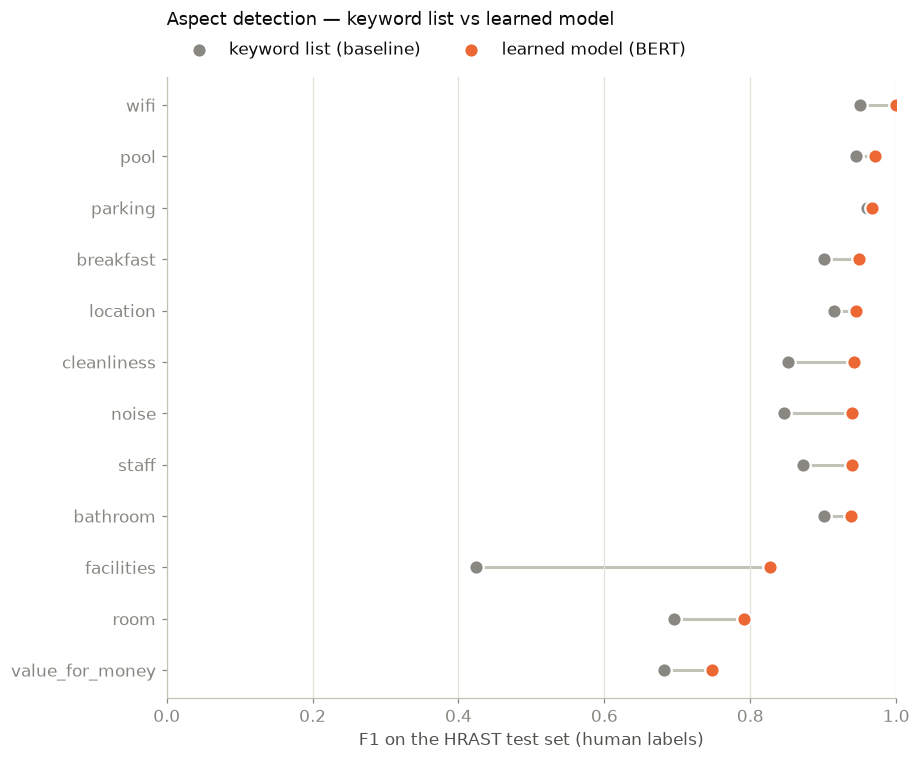

Mean F1 on the shared aspects — keyword: 0.829 | model: 0.913


In [3]:
# HU: Ha a modell már elkészült, nem tanítjuk újra (a mentett teszteredményt töltjük be).
# EN: If the model already exists it is not retrained (the saved test results are loaded).
if not (am.DEFAULT_MODEL_DIR / "thresholds.json").exists():
    result = am.train_aspect_model(asp_data, ASPECTS)
    report, comparison = result["test_report"], result["keyword_comparison"]
    ev.save_table(report, "05_aspect_model_test_report")
    ev.save_table(comparison, "05_aspect_keyword_vs_model")
else:
    print("Aspect model already trained — loading the saved test results.")
    report = pd.read_csv(PATHS.tables / "05_aspect_model_test_report.csv", index_col=0)
    comparison = pd.read_csv(PATHS.tables / "05_aspect_keyword_vs_model.csv", index_col=0)

display(report)
display(comparison)
am.plot_keyword_vs_model(comparison, save_as="05_aspect_keyword_vs_model"); plt.show()
print(f"Mean F1 on the shared aspects — keyword: {comparison['keyword_f1'].mean():.3f} | "
      f"model: {comparison['model_f1'].mean():.3f}")

## 3. 2/a alkalmazása a Booking-mondatokra / Applying 2/a to the Booking sentences

HU: Darabolt, folytatható futás (mint a címkézésnél). Itt nincs emberi címke, ezért a kulcsszólistával való
**egyezést** mérjük (konzisztencia), nem a pontosságot.
EN: Chunked, resumable run (as in labelling). There is no human label here, so we measure **agreement** with the
keyword list (consistency), not accuracy.

In [4]:
sent_asp = am.predict_aspects(sent, cache_name="aspects_field_units")
dl.write_frame(sent_asp, PATHS.labels / "field_units_aspects")
ASPECT_NAMES = am.aspect_names_in(sent_asp)

share = sent_asp[[f"asp_{a}" for a in ASPECT_NAMES]].mean().sort_values(ascending=False)
share.index = share.index.str.replace("asp_", "", regex=False)
display(share.round(4).to_frame("share of sentences"))
print(f"Sentences without any aspect: {(sent_asp['n_aspects'] == 0).mean():.1%}")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

17:17:49 | INFO    | src.bert_labelling | [aspects_field_units] chunk 1/9 (10000 texts)
17:17:54 | INFO    | src.bert_labelling | [aspects_field_units] chunk 2/9 (10000 texts)
17:17:59 | INFO    | src.bert_labelling | [aspects_field_units] chunk 3/9 (10000 texts)
17:18:05 | INFO    | src.bert_labelling | [aspects_field_units] chunk 4/9 (10000 texts)
17:18:10 | INFO    | src.bert_labelling | [aspects_field_units] chunk 5/9 (10000 texts)
17:18:15 | INFO    | src.bert_labelling | [aspects_field_units] chunk 6/9 (10000 texts)
17:18:21 | INFO    | src.bert_labelling | [aspects_field_units] chunk 7/9 (10000 texts)
17:18:26 | INFO    | src.bert_labelling | [aspects_field_units] chunk 8/9 (10000 texts)
17:18:32 | INFO    | src.bert_labelling | [aspects_field_units] chunk 9/9 (5638 texts)
17:18:35 | INFO    | src.aspect_model | Aspects predicted for 85638 sentences | without aspect: 3.3%


,share of sentences
location,0.2229
generic,0.2138
staff,0.1826
room,0.1708
facilities,0.1138
comfort,0.1070
cleanliness,0.1067
breakfast,0.1057
bathroom,0.0540
bed,0.0532


Sentences without any aspect: 3.3%


,mentions,mention_share,negative,neutral,positive,neg_lift,pos_lift
aspect,,,,,,,
lift,550,0.0064,0.7418,0.0545,0.2036,2.6846,0.2998
bathroom,4625,0.0540,0.5351,0.0359,0.4290,1.9366,0.6315
noise,3479,0.0406,0.4815,0.0287,0.4898,1.7424,0.7210
wifi,707,0.0083,0.4752,0.0311,0.4936,1.7199,0.7267
facilities,9748,0.1138,0.4088,0.0493,0.5419,1.4794,0.7977
reception,3024,0.0353,0.3532,0.0427,0.6042,1.2781,0.8894
value_for_money,3510,0.0410,0.3271,0.0533,0.6197,1.1836,0.9122
parking,1713,0.0200,0.3012,0.0665,0.6322,1.0901,0.9307
bar,793,0.0093,0.2913,0.0340,0.6747,1.0542,0.9932


17:18:51 | INFO    | src.evaluation | Table saved: 05_aspect_sentiment_model.csv
17:18:51 | INFO    | src.evaluation | Figure saved: 05_aspect_sentiment_model.png


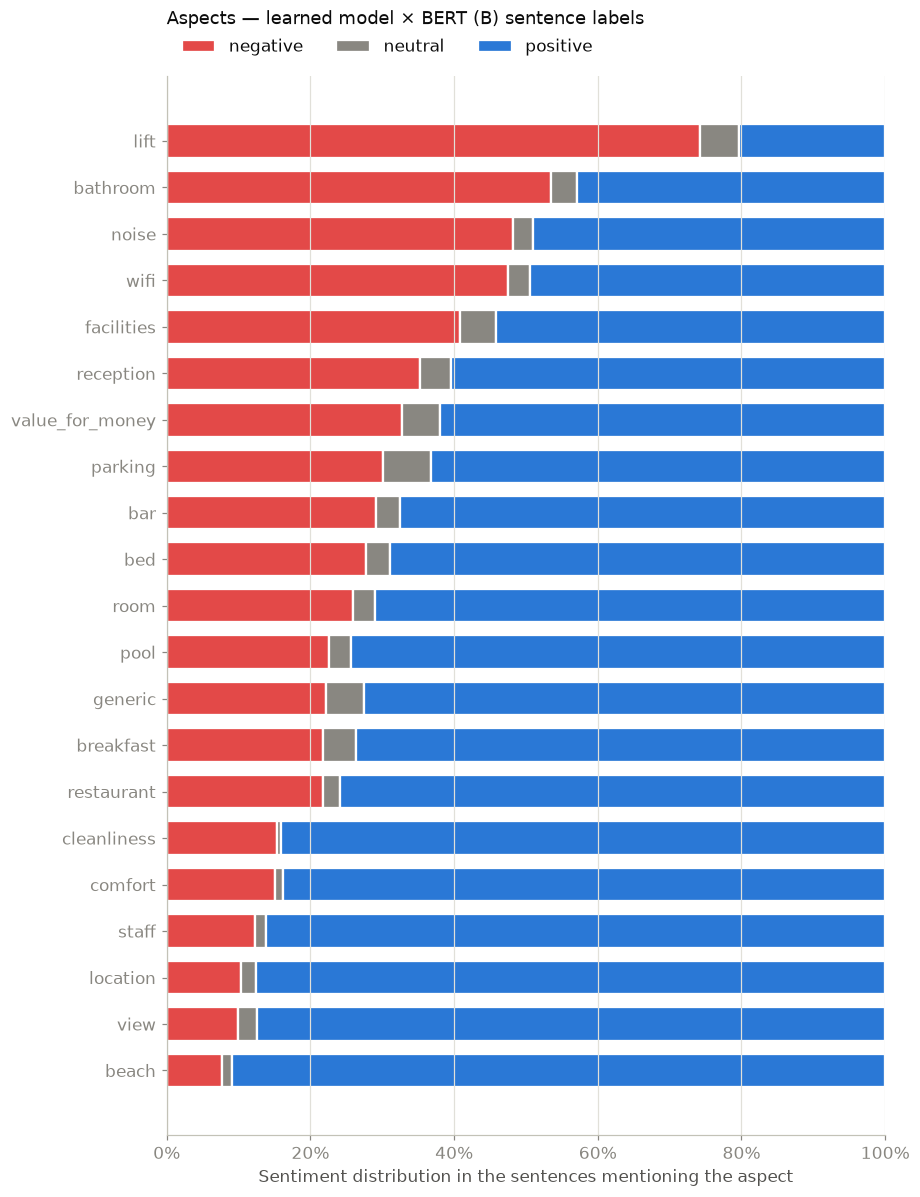

,share_model,share_keyword,agreement,cohen_kappa
aspect,,,,
location,0.2244,0.1769,0.9316,0.7875
staff,0.1835,0.1286,0.9282,0.7291
room,0.1699,0.2241,0.8745,0.6052
facilities,0.1144,0.0683,0.8892,0.3366
cleanliness,0.1063,0.0968,0.9835,0.9097
breakfast,0.1059,0.1191,0.9651,0.8253
bathroom,0.0535,0.0548,0.9834,0.8382
value_for_money,0.0410,0.0367,0.9815,0.7528
noise,0.0401,0.0328,0.9900,0.8572


17:18:54 | INFO    | src.evaluation | Table saved: 05_aspect_keyword_agreement_booking.csv


WindowsPath('C:/Users/seszt/Documents/BCE/7_felev/Szakdolgozat/THESIS/CODE/results/tables/05_aspect_keyword_agreement_booking.csv')

In [5]:
# HU: Aspektus × szentiment a TANULT aspektusokkal (vö. 04-es notebook: kulcsszavas változat).
# EN: Aspect × sentiment with the LEARNED aspects (cf. notebook 04: keyword version).
aspect_sent = asp.aspect_sentiment_table(sent_asp, label_col="B_label", aspects=ASPECT_NAMES,
                                         prefix="asp_", min_count=100)
display(aspect_sent); ev.save_table(aspect_sent, "05_aspect_sentiment_model")
asp.plot_aspect_sentiment(aspect_sent, "Aspects — learned model × BERT (B) sentence labels",
                          save_as="05_aspect_sentiment_model"); plt.show()

agreement = am.keyword_agreement(sent_asp.sample(min(50_000, len(sent_asp)), random_state=CFG.random_seed))
display(agreement); ev.save_table(agreement, "05_aspect_keyword_agreement_booking")

## 4. 2/b — Altémák aspektusonként / Subtopics per aspect

HU: A választott szentimentű (alapból **negatív**) mondatokon minden aspektusra külön témamodell: Sentence-BERT
beágyazás → UMAP → HDBSCAN → c-TF-IDF. A dicséretek altémáihoz állítsd `SENTIMENT = "positive"`-ra, és futtasd
újra innen (a fájlnevek a szentimentet is tartalmazzák).
EN: On sentences of the chosen sentiment (**negative** by default) a separate topic model per aspect: Sentence-BERT
embedding → UMAP → HDBSCAN → c-TF-IDF. For the subtopics of praise set `SENTIMENT = "positive"` and re-run from here
(file names include the sentiment).

In [6]:
SENTIMENT = "negative"
# HU: Kettős szűrés: a vendég a PANASZ-mezőbe írta, ÉS a (B) modell is negatívnak olvassa
#     (így kiesnek a panaszmezőbe írt "nothing, all perfect" típusú egységek).
# EN: Double filter: the guest wrote it into the COMPLAINT field AND the (B) model also reads it as
#     negative (this drops "nothing, all perfect" type units written into the complaint field).
subset = sent_asp[(sent_asp["field_polarity"] == SENTIMENT) & (sent_asp["B_label"] == SENTIMENT)
                  & (sent_asp["n_aspects"] > 0)].reset_index(drop=True)
print(f"{len(subset):,} {SENTIMENT} units with at least one aspect")

embeddings = tm.embed_sentences(subset["sentence"], cache_name=f"emb_{SENTIMENT}_units")
print("Embeddings:", embeddings.shape)

18,507 negative units with at least one aspect


17:19:42 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/modules.json "HTTP/1.1 307 Temporary Redirect"
17:19:42 | WARNING | huggingface_hub.utils._http | Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
17:19:42 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/all-MiniLM-L6-v2/1110a243fdf4706b3f48f1d95db1a4f5529b4d41/modules.json?%2Fsentence-transformers%2Fall-MiniLM-L6-v2%2Fresolve%2Fmain%2Fmodules.json=&etag=%22952a9b81c0bfd99800fabf352f69c7ccd46c5e43%22 "HTTP/1.1 200 OK"
17:19:42 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/config_sentence_transformers.json "HTTP/1.1 307 Temporary Redirect"
17:19:42 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transform

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

17:19:43 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/processor_config.json "HTTP/1.1 404 Not Found"
17:19:44 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/preprocessor_config.json "HTTP/1.1 404 Not Found"
17:19:44 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/video_preprocessor_config.json "HTTP/1.1 404 Not Found"
17:19:44 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/preprocessor_config.json "HTTP/1.1 404 Not Found"
17:19:44 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
17:19:44 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/all-Mini

Embeddings: (18507, 384)


c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
17:20:45 | INFO    | src.topic_modeling | Topics: 29 | noise 18.8% -> 8.8% | NPMI 0.015 | diversity 0.914


,value
n_sentences,18507.0000
n_topics,29.0000
min_cluster_size,185.0000
noise_share_before,0.1883
noise_share_after,0.0883
mean_coherence_npmi,0.0152
topic_diversity,0.9138


,topic,size,share,label,top_terms,coherence_npmi,examples
0,0,1841,0.099476,breakfast / food / restaurant,"breakfast, food, restaurant, bar, not, options, dinner, no, menu, eggs",0.128676,Breakfast was poor quality with limited options || Food wasn’t great - decent selection for breakfast || The breakfa...
1,1,1699,0.091803,shower / water / bathroom,"shower, water, bathroom, toilet, hot, hot water, bath, pressure, small, wet",0.184469,The bathroom was very small and had only a shower || The bathroom was very tired and the shower could have been bett...
2,2,1404,0.075863,noise / noisy / loud,"noise, noisy, loud, hear, night, music, sound, sleep, people, street",0.198680,"Also noise from nearby rooms was significant || The sound isolation was bad, I could hear noises from all rooms near..."
3,3,1074,0.058032,bed / pillows / beds,"bed, pillows, beds, mattress, comfortable, hard, uncomfortable, soft, not comfortable, sofa",0.237853,The bed and pillows weren’t very comfortable || The bed was a bit hard & the pillows were uncomfortable || beds were...
4,4,700,0.037824,air / conditioning / air conditioning,"air, conditioning, air conditioning, cold, ac, hot, room, heating, temperature, warm",0.188970,"The room was too cold due to AC || The room got pretty warm, no AC || The room was too hot and air conditioning didn..."
5,5,744,0.040201,clean / cleaning / cleaned,"clean, cleaning, cleaned, carpet, dirty, room, stains, housekeeping, not clean, not",0.136436,The room wasn's cleaned during our stay || The room was not very clean || The room was not clean enough
6,6,889,0.048036,room / small / room small,"room, small, room small, rooms, rooms small, smaller, family, space, small room, not",0.040456,rooms were quite small || rooms are small || The room was a little bit small for our needs
7,7,653,0.035284,location / far / walk,"location, far, walk, town, road, taxi, walking, city, shuttle, airport",-0.013927,Location is a bit out of the way || The location a bit far from tourist area || The location is little bit away from...
8,8,539,0.029124,towels / soap / towel,"towels, soap, towel, no, paper, dryer, shampoo, washing, laundry, toilet paper",-0.081385,Just two small things: we didn't have towels and there also was no hand soap in the bathroom || Our room had no towe...
9,9,575,0.031069,staff / reception / friendly,"staff, reception, friendly, desk, rude, not friendly, english, phone, not, check",0.076471,The staff at Reception were not very friendly/helpful || Reception staff was not very friendly || Staff interaction ...


17:20:45 | INFO    | src.evaluation | Table saved: 05_negative_topics_overview.csv
17:20:45 | INFO    | src.evaluation | Figure saved: 05_negative_topics_overview.png


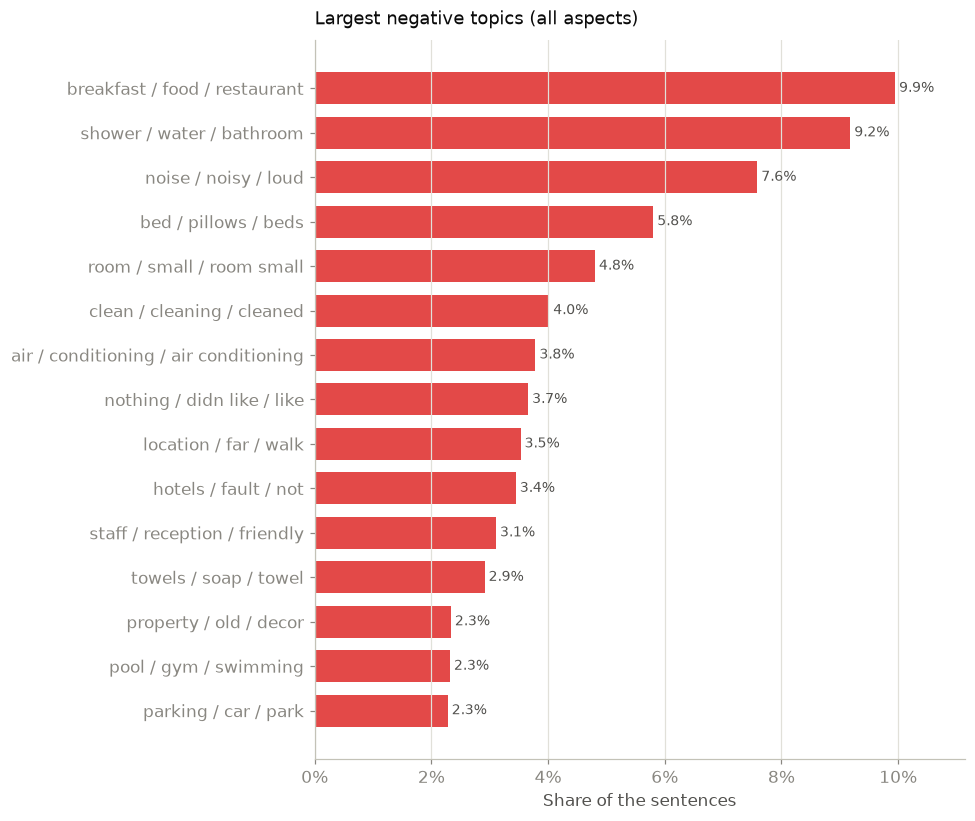

In [7]:
# HU: Áttekintő témamodell az összes ilyen mondaton (mintán) — aspektustól függetlenül.
# EN: Overview topic model on all such sentences (on a sample) — independent of the aspect.
rng = np.random.default_rng(CFG.random_seed)
overview_rows = np.sort(rng.choice(len(subset), size=min(30_000, len(subset)), replace=False))
overview = tm.fit_topics(subset["sentence"].iloc[overview_rows], embeddings[overview_rows])
display(pd.Series(overview.metrics).to_frame("value"))
display(overview.topic_info.head(20))
ev.save_table(overview.topic_info, f"05_{SENTIMENT}_topics_overview")
tm.plot_topic_sizes(overview.topic_info, f"Largest {SENTIMENT} topics (all aspects)", sentiment=SENTIMENT,
                    save_as=f"05_{SENTIMENT}_topics_overview"); plt.show()

17:21:27 | INFO    | src.topic_modeling | room             3235 sentences
c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
17:21:44 | INFO    | src.topic_modeling | Topics: 19 | noise 20.5% -> 2.7% | NPMI -0.122 | diversity 0.795
17:21:44 | INFO    | src.topic_modeling | location         1362 sentences
c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
17:21:47 | INFO    | src.topic_modeling | Topics: 2 | noise 1.5% -> 1.5% | NPMI -0.148 | diversity 0.950
17:21:47 | INFO    | src.topic_modeling | staff            1545 sentences
c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridd

,n_sentences,n_topics,min_cluster_size,noise_share_before,noise_share_after,mean_coherence_npmi,topic_diversity
aspect,,,,,,,
room,3235,19,40,0.2053,0.0269,-0.1218,0.7947
location,1362,2,40,0.0154,0.0154,-0.1477,0.9500
staff,1545,10,40,0.3010,0.1353,-0.1210,0.7400
cleanliness,1303,10,40,0.1259,0.0261,-0.1726,0.7700
facilities,3530,21,40,0.1411,0.0544,-0.1307,0.8762
comfort,1125,4,40,0.0000,0.0000,-0.2086,0.8500
breakfast,1542,11,40,0.1751,0.0188,-0.1128,0.7909
bathroom,2276,20,40,0.1762,0.0101,-0.1168,0.8150
noise,1517,15,40,0.2432,0.0237,-0.1206,0.7133


17:22:34 | INFO    | src.evaluation | Table saved: 05_negative_subtopic_quality.csv
17:22:34 | INFO    | src.evaluation | Table saved: 05_negative_subtopics.csv


Main aspects: ['facilities', 'room', 'bathroom', 'staff', 'breakfast', 'noise', 'location', 'cleanliness', 'bed', 'comfort', 'value_for_money', 'reception', 'parking', 'pool', 'lift', 'restaurant', 'wifi']


17:22:37 | INFO    | src.evaluation | Figure saved: 05_negative_subtopics_by_aspect.png


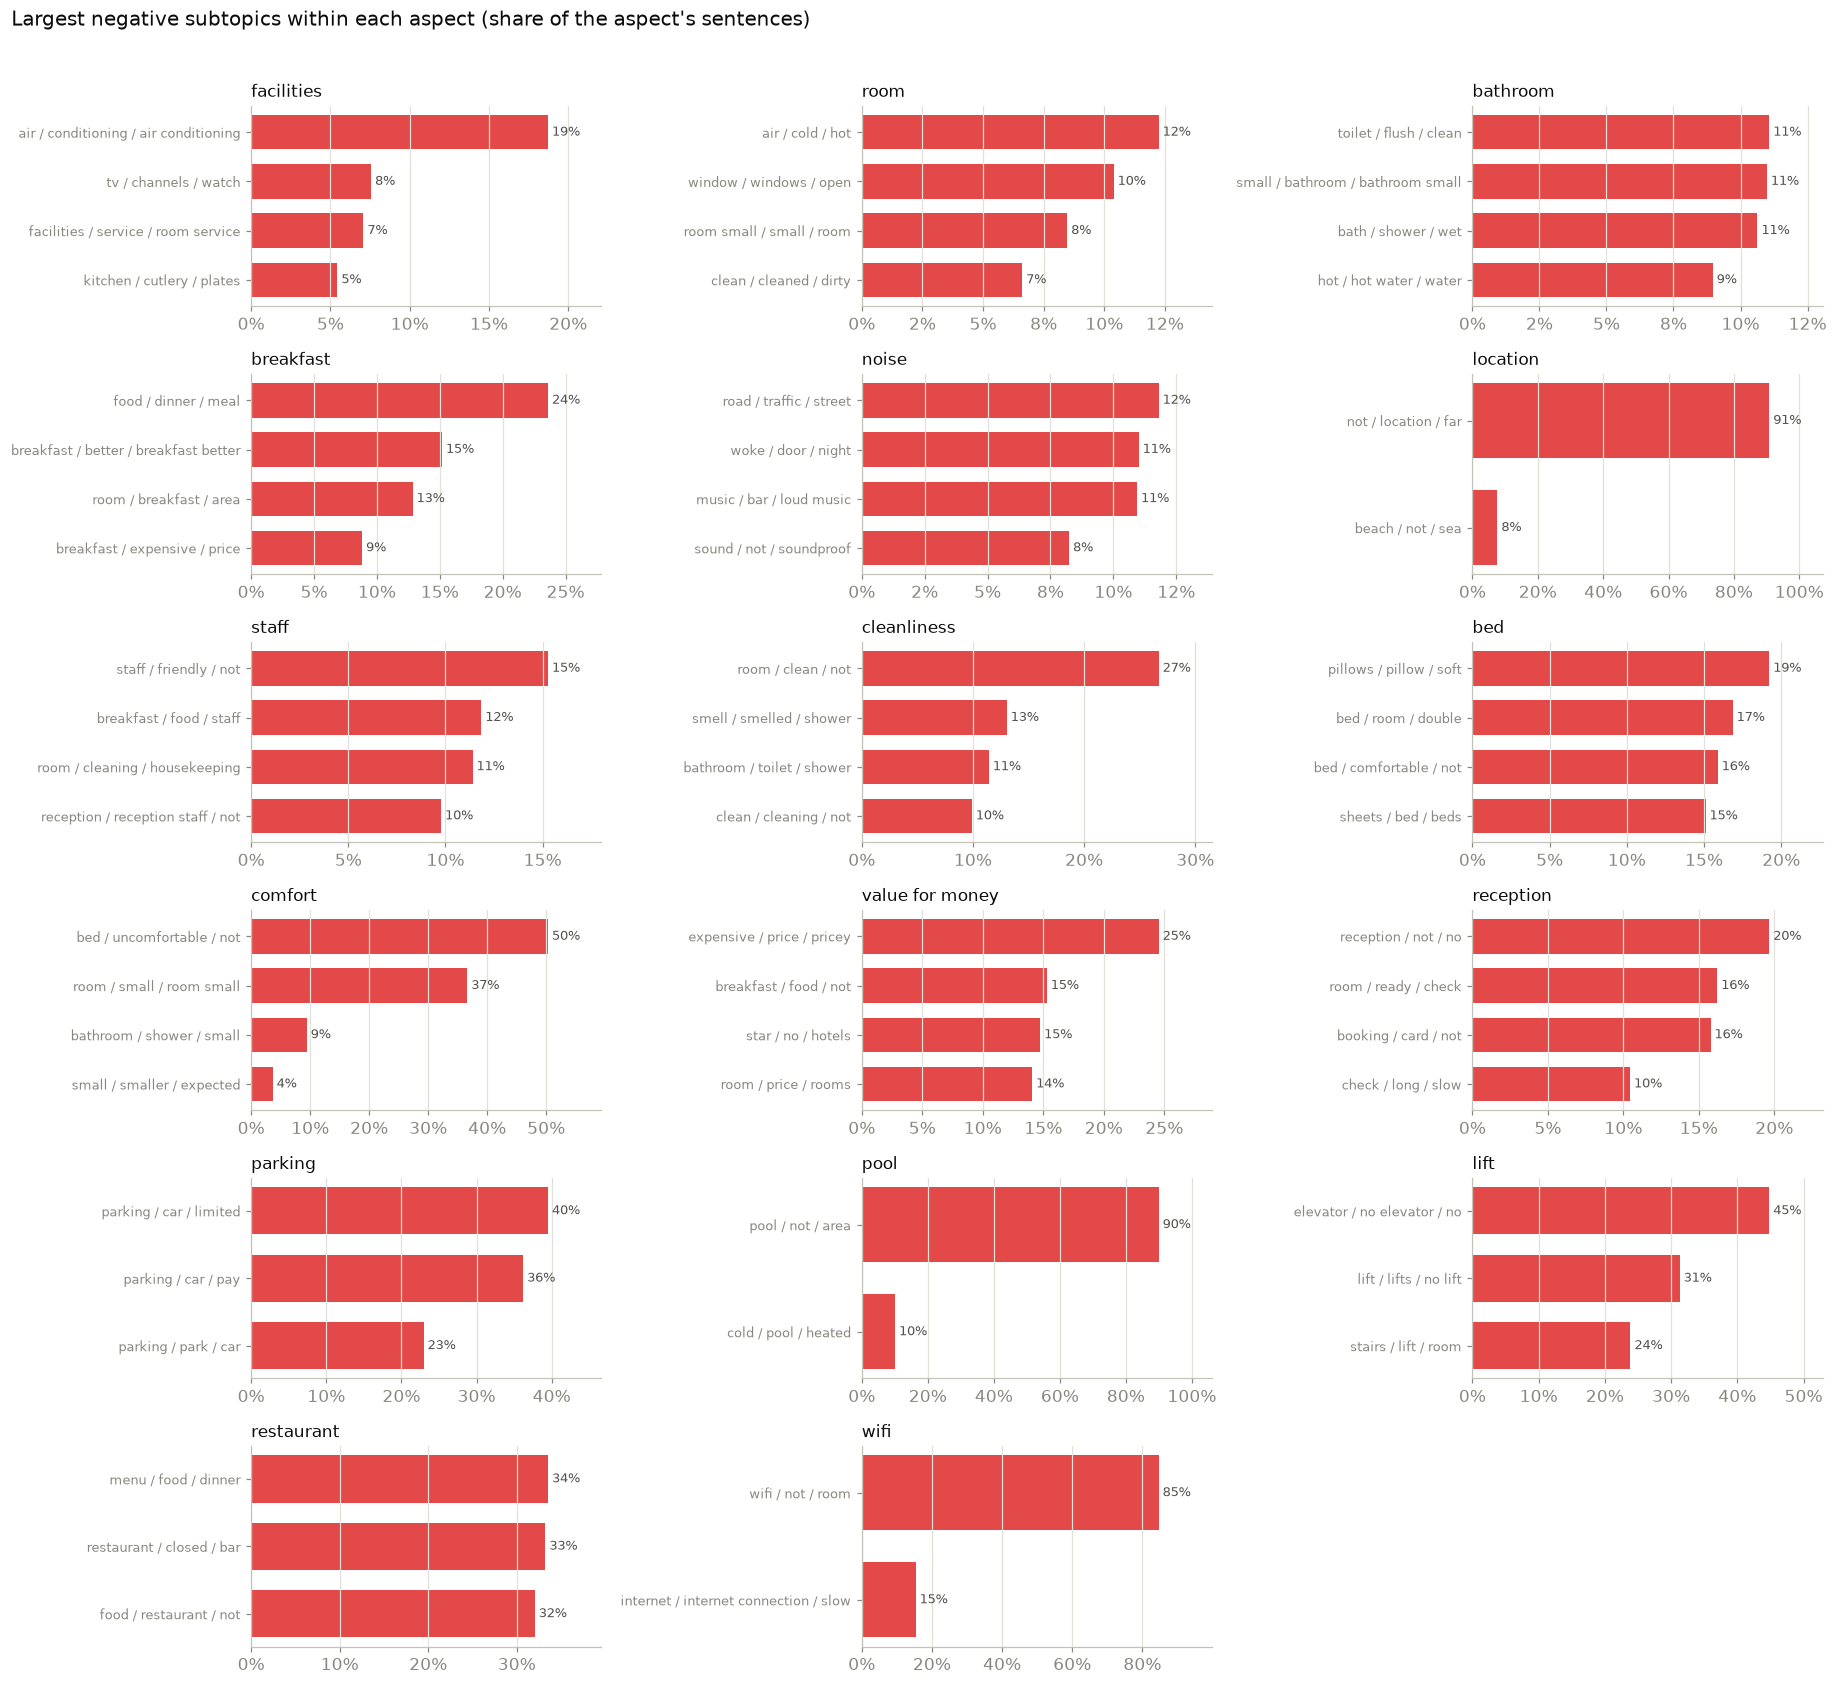

In [8]:
topic_table, assignments, topic_summary = tm.fit_subtopics_per_aspect(subset, embeddings, ASPECT_NAMES)
display(topic_summary)
ev.save_table(topic_summary, f"05_{SENTIMENT}_subtopic_quality")
# HU: A legtöbb mondatú, legalább egy altémát adó aspektusok. / EN: Aspects with most sentences and at least one subtopic.
MAIN_ASPECTS = (topic_summary[topic_summary["n_topics"] > 0]
                .sort_values("n_sentences", ascending=False).index.tolist())
print("Main aspects:", MAIN_ASPECTS)
ev.save_table(topic_table, f"05_{SENTIMENT}_subtopics")
dl.write_frame(assignments.assign(review_id=subset["review_id"].iloc[assignments["row"]].to_numpy(),
                                  sentence=subset["sentence"].iloc[assignments["row"]].to_numpy()),
               PATHS.labels / f"subtopic_assignments_{SENTIMENT}")

tm.plot_aspect_subtopics(topic_table, top_k=4, sentiment=SENTIMENT,
                         save_as=f"05_{SENTIMENT}_subtopics_by_aspect"); plt.show()

In [9]:
# HU: Olvasd el az altémákat a példamondatokkal! / EN: Read the subtopics with the example sentences!
for aspect in MAIN_ASPECTS[:4]:
    print(f"\n=== {aspect} ===")
    for _, r in topic_table[topic_table["aspect"] == aspect].head(6).iterrows():
        print(f"  [{r['topic']}] {r['label']}  ({r['share_within_aspect']:.0%}, NPMI {r['coherence_npmi']:.2f})")
        print(f"       e.g. {r['examples'].split(' || ')[0][:150]}")


=== facilities ===
  [0] air / conditioning / air conditioning  (19%, NPMI -0.05)
       e.g. The room was too hot and air conditioning didn’t seem to do much
  [1] tv / channels / watch  (8%, NPMI 0.03)
       e.g. The tv in the room couldn’t be cast to and didn’t have wi-fi so you could only watch a few channels
  [2] facilities / service / room service  (7%, NPMI -0.07)
       e.g. Lack of amenities (was basically a set of rooms over a bar)
  [3] kitchen / cutlery / plates  (5%, NPMI -0.27)
       e.g. The kitchen was not well equipped, we were missing basic cooking equipment (proper knives, cutting boards, kitchen towels, basic spices, coffee machin
  [4] coffee / tea / tea coffee  (5%, NPMI 0.05)
       e.g. No tea/coffee facilities in the room which would have been great
  [5] water / hot water / hot  (5%, NPMI -0.23)
       e.g. Not having a tap with drinking water in the room was odd

=== room ===
  [0] air / cold / hot  (12%, NPMI 0.08)
       e.g. The room was very warm, the

In [10]:
# HU: OPCIONÁLIS: beszédes nevek a dolgozatba (a témaszámokat a fenti listából vedd).
# EN: OPTIONAL: meaningful names for the thesis (take the topic numbers from the list above).
TOPIC_NAMES = {
    # ("bathroom", 0): "no hot water",
    # ("noise", 1): "thin walls / neighbours",
}
if TOPIC_NAMES:
    topic_table, assignments = tm.rename_topics(topic_table, assignments, TOPIC_NAMES)
    ev.save_table(topic_table, f"05_{SENTIMENT}_subtopics")

### Stabilitás / Stability

HU: Ugyanaz a modell három különböző véletlen kezdőértékkel a három legnagyobb aspektuson. A korrigált Rand-index
(ARI) 0,5 felett azt jelzi, hogy a témák nem a véletlen termékei.
EN: The same model with three different random seeds on the three largest aspects. An adjusted Rand index (ARI)
above 0.5 shows that the topics are not products of chance.

In [11]:
stability_rows = []
for aspect in MAIN_ASPECTS[:3]:
    rows = np.where(subset[f"asp_{aspect}"].to_numpy() == 1)[0]
    rows = np.sort(np.random.default_rng(CFG.random_seed).choice(
        rows, size=min(len(rows), CFG.topic_sample_per_aspect), replace=False))
    table = tm.topic_stability(subset["sentence"].iloc[rows], embeddings[rows])
    stability_rows.append({"aspect": aspect, "mean_pairwise_ari": table.attrs["mean_pairwise_ari"],
                           "n_topics_per_seed": table["n_topics"].tolist()})
stability = pd.DataFrame(stability_rows).set_index("aspect").round(3)
display(stability); ev.save_table(stability, f"05_{SENTIMENT}_subtopic_stability")

c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
17:24:30 | INFO    | src.topic_modeling | Topics: 21 | noise 14.1% -> 5.4% | NPMI -0.131 | diversity 0.876
c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
17:24:44 | INFO    | src.topic_modeling | Topics: 22 | noise 17.1% -> 6.6% | NPMI -0.118 | diversity 0.891
c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
17:24:59 | INFO    | src.topic_modeling | Topics: 23 | noise 16.4% -> 6.1% | NPMI -0.129 | diversity 0.870
17:24:59 | INFO    | src.topic_modeling | S

,mean_pairwise_ari,n_topics_per_seed
aspect,,
facilities,0.923,"[21, 22, 23]"
room,0.845,"[19, 21, 22]"
bathroom,0.441,"[20, 22, 14]"


17:25:58 | INFO    | src.evaluation | Table saved: 05_negative_subtopic_stability.csv


WindowsPath('C:/Users/seszt/Documents/BCE/7_felev/Szakdolgozat/THESIS/CODE/results/tables/05_negative_subtopic_stability.csv')

## 5. Panasztérkép / Complaint map

HU: Egy aspektus altémáinak aránya szegmensenként, liftként: 1 felett az altéma az adott szegmensben gyakoribb,
mint átlagosan. Például: a szállodákban a „vékony fal” vagy az apartmanokban a „nincs meleg víz” a jellemzőbb?
EN: Share of an aspect's subtopics per segment, as lift: above 1 the subtopic is more common in that segment than on
average. E.g.: is "thin walls" more typical in hotels, or "no hot water" in apartments?

17:26:09 | INFO    | src.evaluation | Table saved: 05_negative_map_facilities_by_accommodation_type.csv
17:26:11 | INFO    | src.evaluation | Figure saved: 05_negative_map_facilities_by_accommodation_type.png


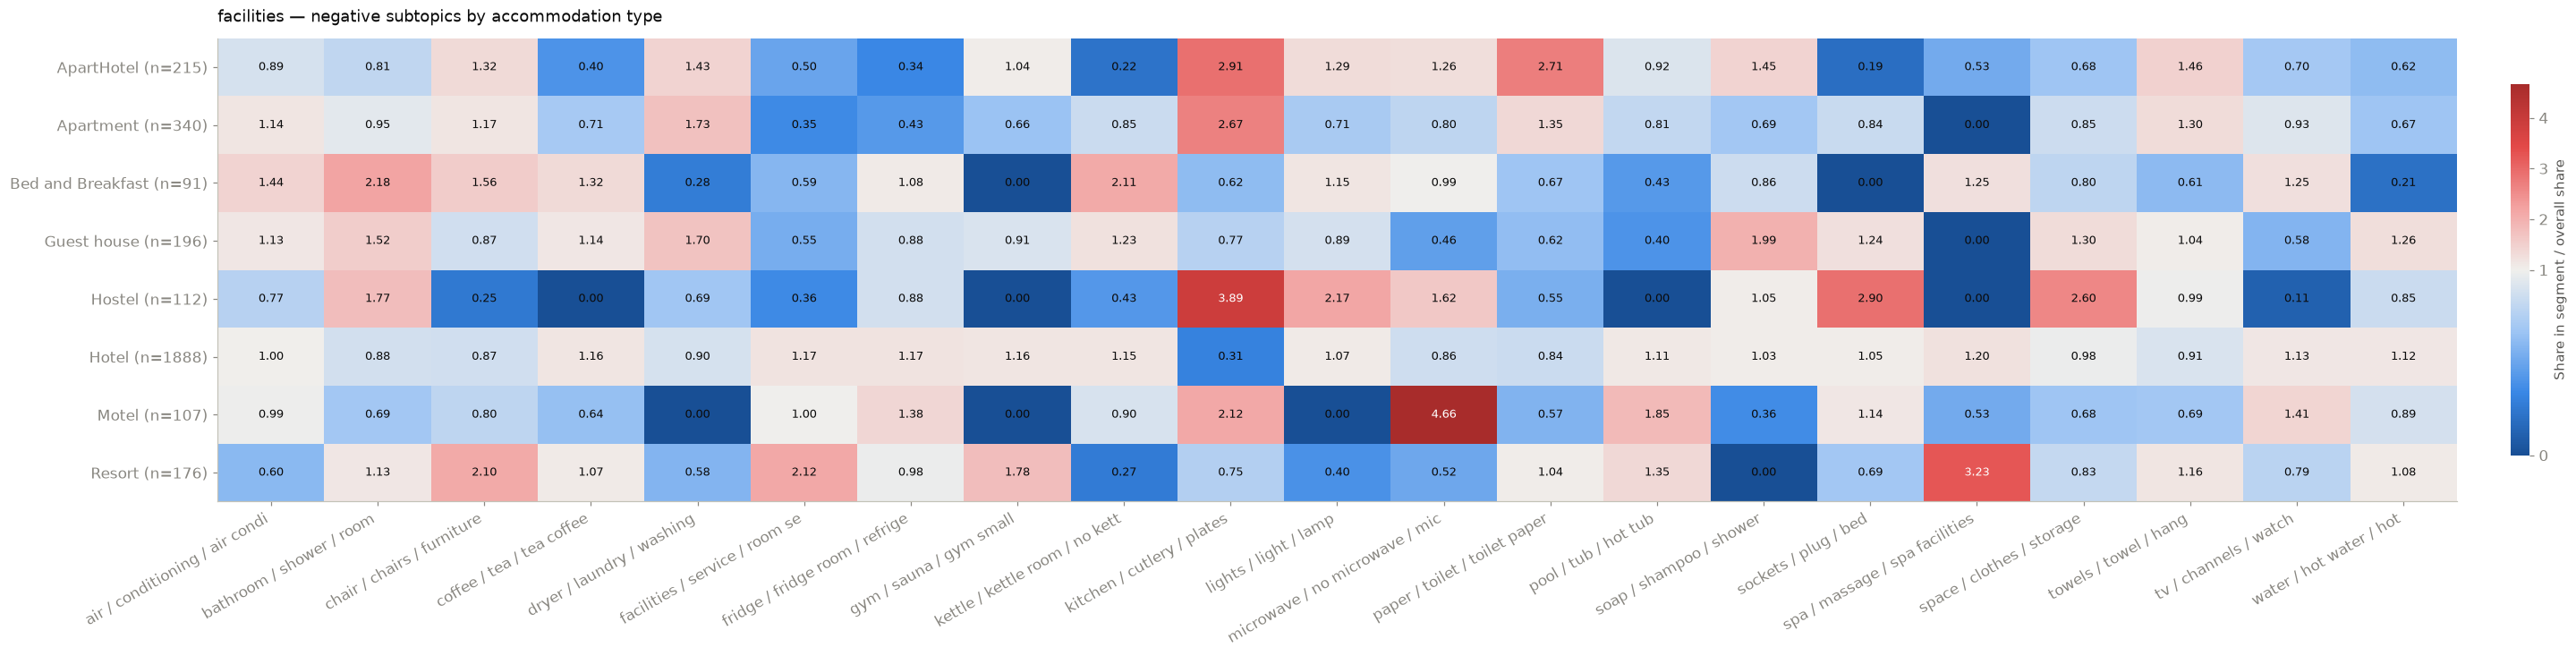

17:26:12 | INFO    | src.evaluation | Table saved: 05_negative_map_facilities_by_accommodation_country.csv
17:26:14 | INFO    | src.evaluation | Figure saved: 05_negative_map_facilities_by_accommodation_country.png


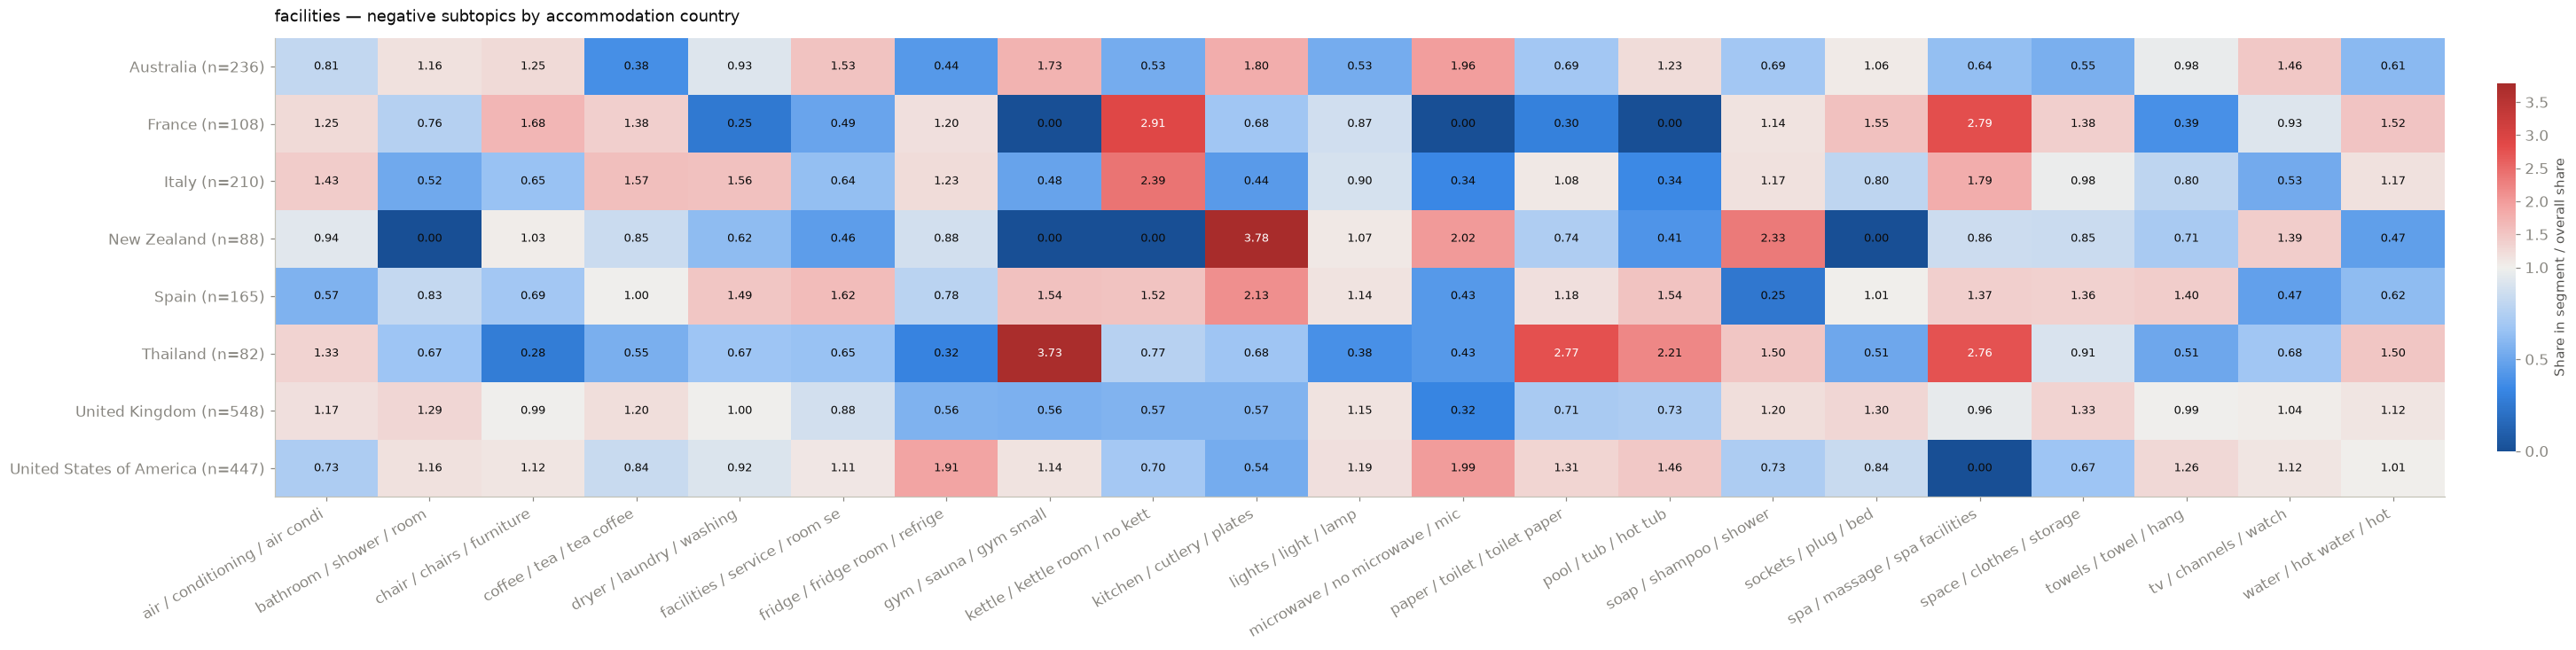

17:26:15 | INFO    | src.evaluation | Table saved: 05_negative_map_room_by_accommodation_type.csv
17:26:16 | INFO    | src.evaluation | Figure saved: 05_negative_map_room_by_accommodation_type.png


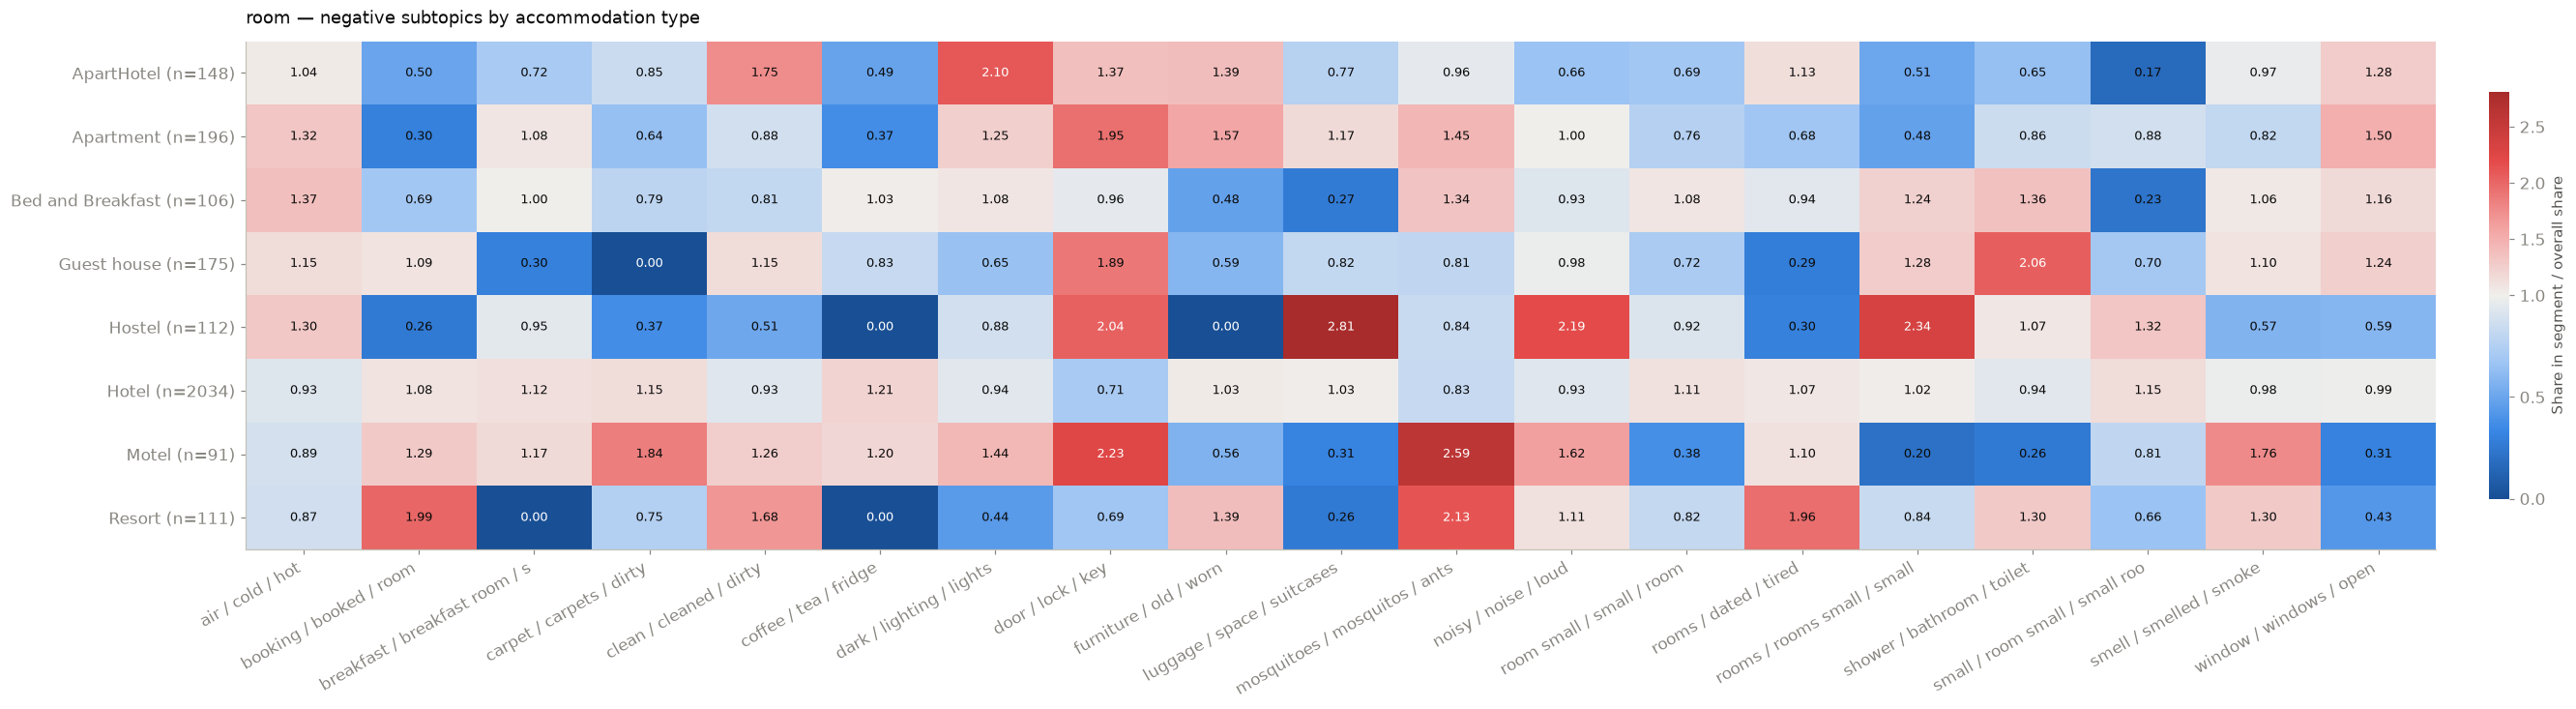

17:26:17 | INFO    | src.evaluation | Table saved: 05_negative_map_room_by_accommodation_country.csv
17:26:19 | INFO    | src.evaluation | Figure saved: 05_negative_map_room_by_accommodation_country.png


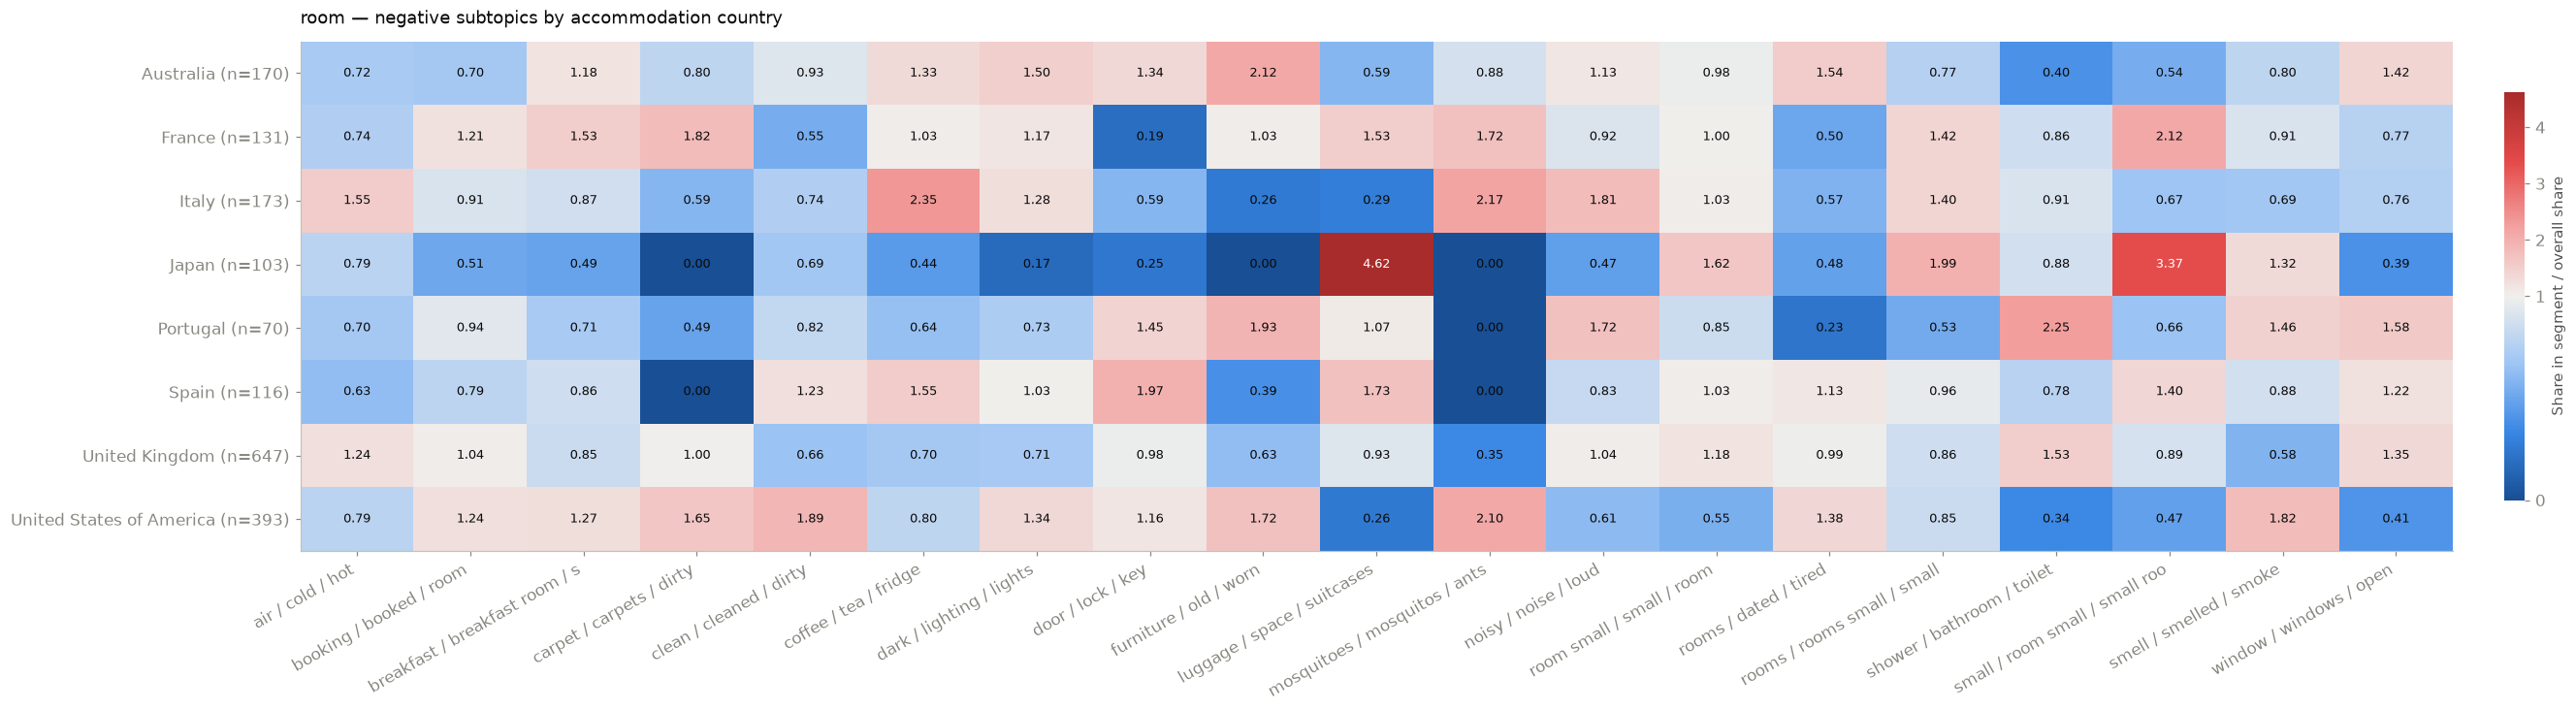

17:26:20 | INFO    | src.evaluation | Table saved: 05_negative_map_bathroom_by_accommodation_type.csv
17:26:22 | INFO    | src.evaluation | Figure saved: 05_negative_map_bathroom_by_accommodation_type.png


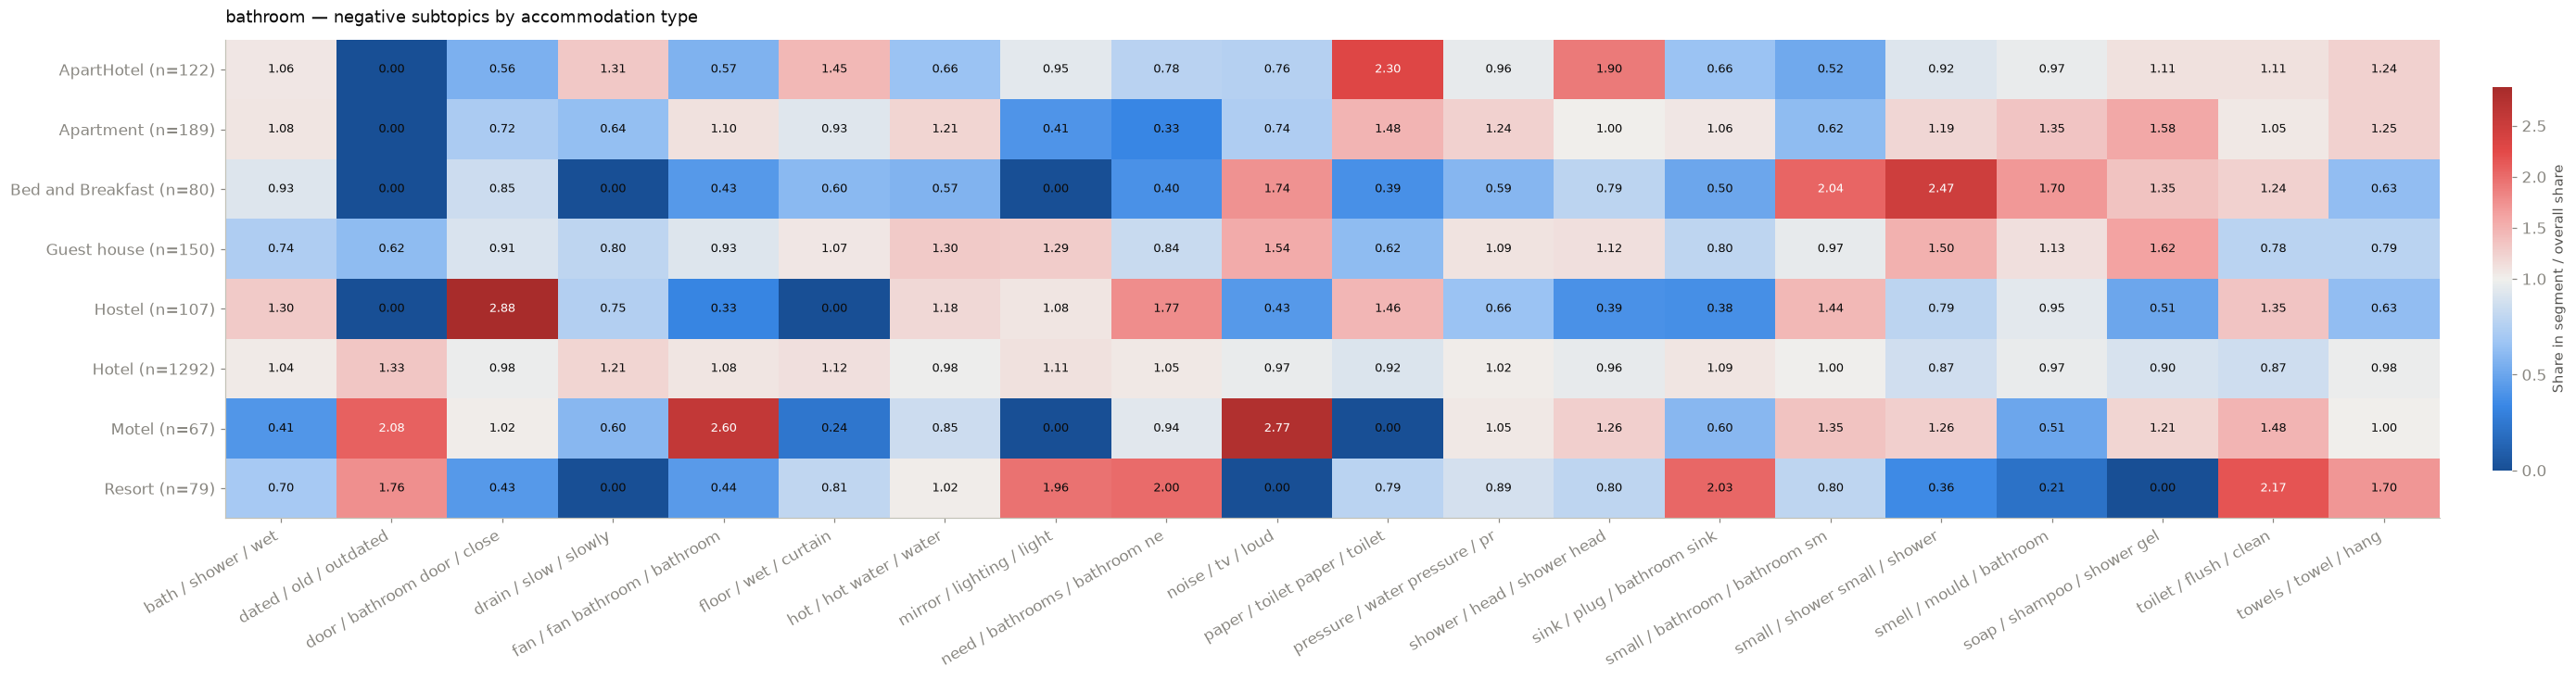

17:26:23 | INFO    | src.evaluation | Table saved: 05_negative_map_bathroom_by_accommodation_country.csv
17:26:25 | INFO    | src.evaluation | Figure saved: 05_negative_map_bathroom_by_accommodation_country.png


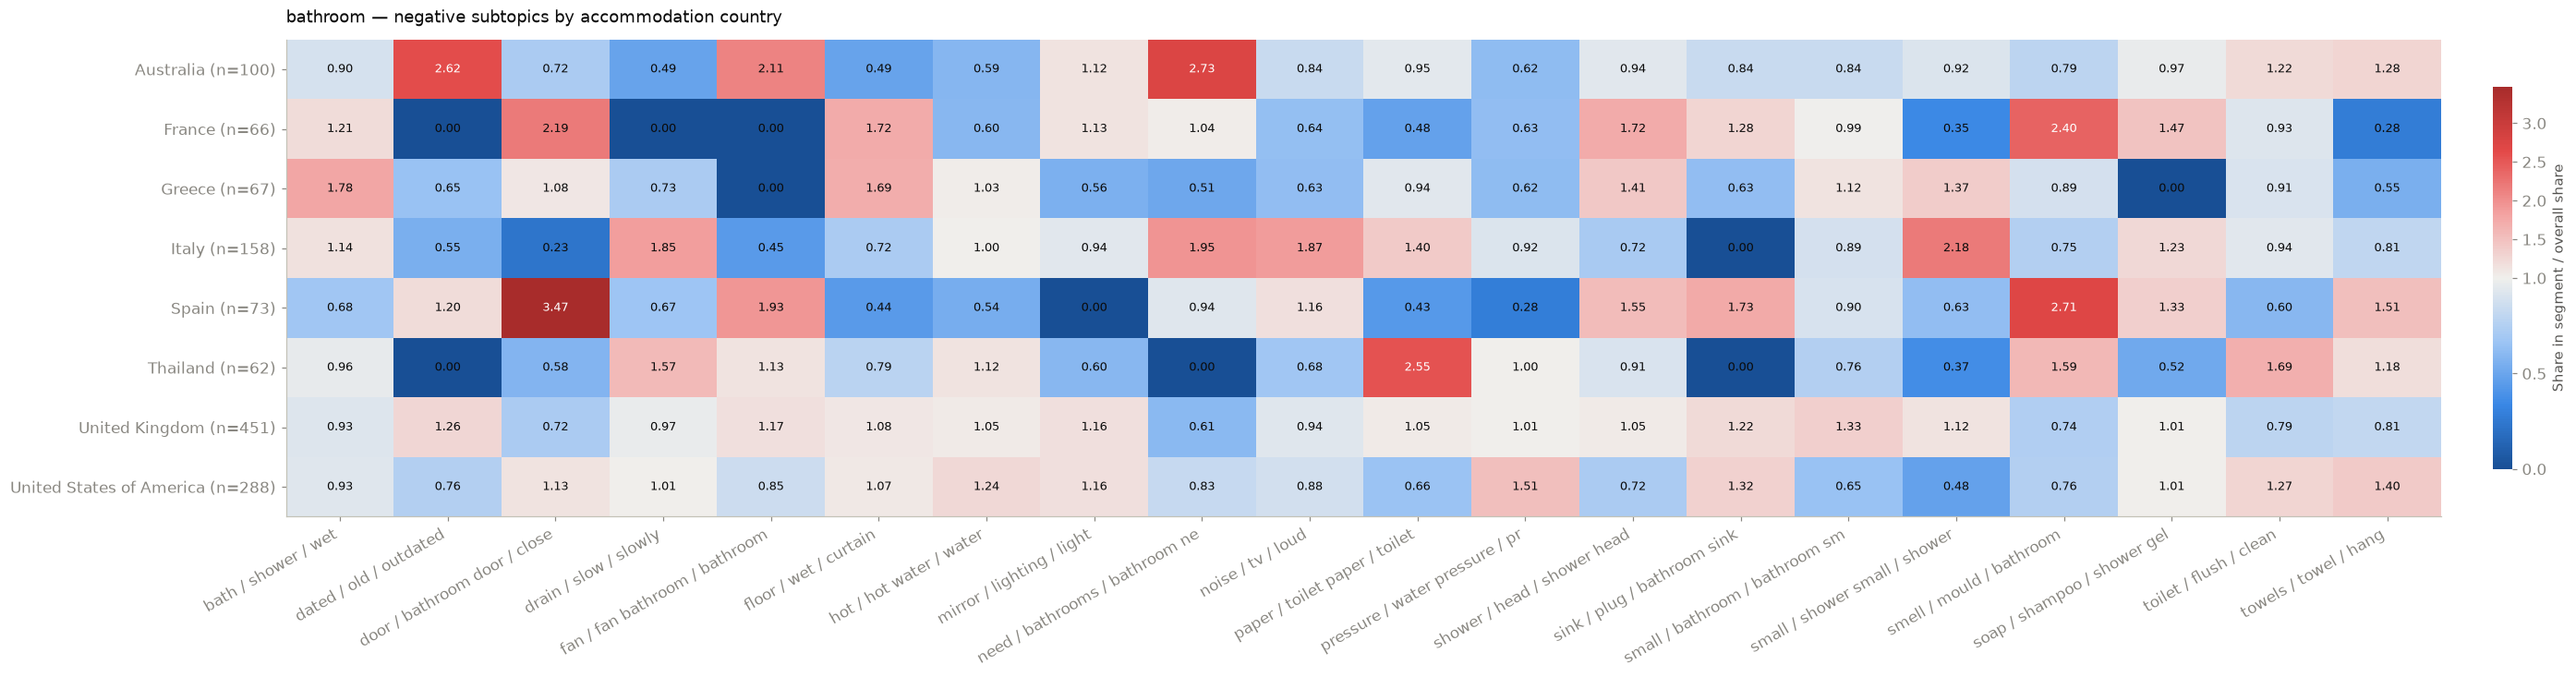

In [12]:
for aspect in MAIN_ASPECTS[:3]:
    for segment in ["accommodation_type", "accommodation_country"]:
        lift = tm.segment_table(assignments, subset, aspect, segment, min_count=50, top_segments=8)
        if lift.empty:
            continue
        ev.save_table(lift, f"05_{SENTIMENT}_map_{aspect}_by_{segment}")
        tm.plot_segment_heatmap(lift, f"{aspect.replace('_', ' ')} — {SENTIMENT} subtopics by {segment.replace('_', ' ')}",
                                save_as=f"05_{SENTIMENT}_map_{aspect}_by_{segment}")
        plt.show()

## 6. Kézi ellenőrzés / Manual check

HU: Témánként 20 véletlen mondat Excelben; a `fits` oszlopba 1 (illik a témához) vagy 0 kerül. Az első futás
exportál, a kitöltés után a második futás kiszámolja a témánkénti pontosságot. (Kb. 1–2 óra a nagyobb aspektusokra.)
EN: 20 random sentences per topic in Excel; put 1 (fits the topic) or 0 into the `fits` column. The first run exports,
after filling it in the second run computes the per-topic precision. (About 1–2 hours for the larger aspects.)

In [13]:
check_file = PATHS.annotation / f"topic_check_{SENTIMENT}_units.xlsx"
if not check_file.exists():
    top_aspects = MAIN_ASPECTS[:4]
    tm.export_topic_check(topic_table[topic_table["aspect"].isin(top_aspects)],
                          assignments[assignments["aspect"].isin(top_aspects)], subset,
                          filename=check_file.name)
    print("Exported — fill in the 'fits' column, then re-run this cell.")
else:
    precision = tm.evaluate_topic_check(check_file.name)
    display(precision); ev.save_table(precision, f"05_{SENTIMENT}_topic_precision")

17:27:17 | INFO    | src.topic_modeling | Topic check exported: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\data\annotation\topic_check_negative_units.xlsx (1400 sentences)


Exported — fill in the 'fits' column, then re-run this cell.


---
## Összefoglalás / Summary

| Kimenet / Output | Mire jó? / Purpose |
|---|---|
| `05_aspect_keyword_vs_model` (tábla + ábra) | **2/a mérése:** tanult modell vs. kulcsszólista, emberi címkén |
| `05_aspect_model_test_report` | aspektusonkénti precision / recall / F1 |
| `05_aspect_sentiment_model` | aspektus × szentiment a tanult aspektusokkal |
| `05_<sentiment>_subtopics` + `_subtopics_by_aspect.png` | **2/b:** altémák aspektusonként |
| `05_<sentiment>_subtopic_quality`, `_stability` | koherencia, diverzitás, stabilitás |
| `05_<sentiment>_map_*` | **panasztérkép** szegmensenként |
| `05_<sentiment>_topic_precision` | kézi ellenőrzés: témánkénti pontosság |